# Simulation 22: Heuristics vs. Baselines Run time

TJ Kim
8/29/22

Updated: 4/20/21 -- For crawdad mobility instead of one mobility

Run the second simulation with the following considerations.

- 10 Servers, 10 TS, 15 Users --> increase servers to 20 and users to 40
- Use ONE-mobility --> crawdad
- Job lengths: vr = 10-15, Assist = 5-10, AR = 10-15
- We share the same users and jobs between simulations

Resources: Normal
- All jobs are run with standard Quantity
- 14 level 1, 5 level 2, 1 level 3

In [1]:
from IPython.core.debugger import set_trace

# Import Generic Classes
import numpy as np
import copy
import pickle
import random
import time

# Import All Custom Classes
import os, sys
sys.path.append(os.path.pardir+"/classes")
sys.path.append(os.path.pardir+"/solvers")
sys.path.append(os.path.pardir+"/one_mobility")
sys.path.append(os.path.curdir + "/sim_store/sim22")
sys.path.append(os.path.pardir+"/crawdad_mobility")


from Server import *
from User import *
from Link import *
from Job import *
from Migration_Plans import *
from Cost_Recordings import *

from load_crawdad_usr import *

from sim22_setting import *


# Import Solver Classes
from Optim_PlanGenerator import *
from SeqGreedy_PlanGenerator import *
from Myopic_PlanGenerator import *
from Naive_PlanGenerator import *
from Cloud_PlanGenerator import *

In [2]:
# Load Crawdad data
# Load All 12 users and trim their info
db_names = []
for i in range(1,13):
    if i != 8 and i != 13:
        db_names += ['LifeMap_GS'+str(i)+'.db']

db = []
for name in db_names:
    name = os.path.pardir+ "/crawdad_mobility/" + name
    print(name)
    df,trace = load_usr(name)
    db += [trace]

../crawdad_mobility/LifeMap_GS1.db
../crawdad_mobility/LifeMap_GS2.db
../crawdad_mobility/LifeMap_GS3.db
../crawdad_mobility/LifeMap_GS4.db
../crawdad_mobility/LifeMap_GS5.db
../crawdad_mobility/LifeMap_GS6.db
../crawdad_mobility/LifeMap_GS7.db
../crawdad_mobility/LifeMap_GS9.db
../crawdad_mobility/LifeMap_GS10.db
../crawdad_mobility/LifeMap_GS11.db
../crawdad_mobility/LifeMap_GS12.db


In [3]:
num_trials = 300
Batch_cost_stores = []
SG_cost_stores = []
Naive_cost_stores = []
Myopic_cost_stores = []
Cloud_cost_stores = []

Batch_time_stores = []
SG_time_stores = []
Naive_time_stores = []
Myopic_time_stores = []
Cloud_time_stores = []

for i in range(num_trials):
    
    print("Trial Number:",i)
    
    print("limited")
    users, servers, links, jobs, sim_param = simulation_setting(db)

    while True:
        try:
            # Make Users
            users, servers, links, jobs, sim_param = simulation_setting(db)
            # Make Batch Prob 
            print("batch_prob...")
            start = time.process_time()
            Batch_prob = SeqGreedy_PlanGenerator(users, servers, links, jobs, sim_param)
            Batch_plan = Migration_Plans(users,jobs,sim_param)
            Batch_plan.from_seq_greedy(Batch_prob)
            Batch_cost_stores += [Cost_Recordings(Batch_plan)]
            end = time.process_time()
            Batch_time_stores += [end-start]
            print("done!")
            
            break
        except:
            print("batch_broken, repeating with new users")
            continue
            
    # Make SG Prob
    refresh_rate = [0,0]
    refresh = False

    jobs2 = copy.deepcopy(jobs)
    for j in range(len(jobs2)):
        jobs2[j].info_from_usr(users[j],refresh_rate,refresh)
    
    print("SG prob...")
    start = time.process_time()
    SG_prob = SeqGreedy_PlanGenerator(users, servers, links, jobs2, sim_param)
    SG_plan = Migration_Plans(users,jobs2,sim_param)
    SG_plan.from_seq_greedy(SG_prob)
    SG_cost_stores = [Cost_Recordings(SG_plan)]
    end = time.process_time()
    SG_time_stores += [end-start]
    print("done!")
    
    # Make Cloud Prob
    print("Cloud prob...")
    start = time.process_time()
    Cloud_prob = Cloud_PlanGenerator(users, servers, links, jobs, sim_param)
    Cloud_plan = Migration_Plans(users,jobs,sim_param)
    Cloud_plan.from_seq_greedy(Cloud_prob)
    Cloud_cost_stores = [Cost_Recordings(Cloud_plan)]
    end = time.process_time()
    Cloud_time_stores += [end-start]
    print("done!")
    
    # Make Naive Prob
    print("Naive prob...")
    start = time.process_time()
    Naive_prob = Naive_PlanGenerator(users, servers, links, jobs, sim_param)
    Naive_plan = Migration_Plans(users,jobs,sim_param)
    Naive_plan.from_seq_greedy(Naive_prob)
    Naive_cost_stores = [Cost_Recordings(Naive_plan)]
    end = time.process_time()
    Naive_time_stores += [end-start]
    print("done!")
    
    # Make Myopic Prob
    print("Myopic prob...")
    start = time.process_time()
    Myopic_prob = Myopic_PlanGenerator(users, servers, links, jobs, sim_param)
    Myopic_plan = Migration_Plans(users,jobs,sim_param)
    Myopic_plan.from_seq_greedy(Myopic_prob)
    Myopic_cost_stores = [Cost_Recordings(Myopic_plan)]
    end = time.process_time()
    Myopic_time_stores += [end-start]
    print("done!")

   

Trial Number: 0
limited
batch_prob...
done!
SG prob...
done!
Cloud prob...
done!
Naive prob...
done!
Myopic prob...
done!
Trial Number: 1
limited
batch_prob...
done!
SG prob...
done!
Cloud prob...
done!
Naive prob...
done!
Myopic prob...
done!
Trial Number: 2
limited
batch_prob...
done!
SG prob...
done!
Cloud prob...
done!
Naive prob...
done!
Myopic prob...
done!
Trial Number: 3
limited
batch_prob...
done!
SG prob...
done!
Cloud prob...
done!
Naive prob...
done!
Myopic prob...
done!
Trial Number: 4
limited
batch_prob...
not enough resources, simulation broken
batch_broken, repeating with new users
batch_prob...
done!
SG prob...
done!
Cloud prob...
done!
Naive prob...
done!
Myopic prob...
done!
Trial Number: 5
limited
batch_prob...
done!
SG prob...
done!
Cloud prob...
done!
Naive prob...
done!
Myopic prob...
done!
Trial Number: 6
limited
batch_prob...
done!
SG prob...
done!
Cloud prob...
done!
Naive prob...
done!
Myopic prob...
done!
Trial Number: 7
limited
batch_prob...
done!
SG prob..

done!
Naive prob...
done!
Myopic prob...
done!
Trial Number: 52
limited
batch_prob...
done!
SG prob...
done!
Cloud prob...
done!
Naive prob...
done!
Myopic prob...
done!
Trial Number: 53
limited
batch_prob...
not enough resources, simulation broken
batch_broken, repeating with new users
batch_prob...
done!
SG prob...
done!
Cloud prob...
done!
Naive prob...
done!
Myopic prob...
done!
Trial Number: 54
limited
batch_prob...
done!
SG prob...
done!
Cloud prob...
done!
Naive prob...
done!
Myopic prob...
done!
Trial Number: 55
limited
batch_prob...
done!
SG prob...
done!
Cloud prob...
done!
Naive prob...
done!
Myopic prob...
done!
Trial Number: 56
limited
batch_prob...
not enough resources, simulation broken
batch_broken, repeating with new users
batch_prob...
done!
SG prob...
done!
Cloud prob...
done!
Naive prob...
done!
Myopic prob...
done!
Trial Number: 57
limited
batch_prob...
not enough resources, simulation broken
batch_broken, repeating with new users
batch_prob...
done!
SG prob...
don

done!
SG prob...
done!
Cloud prob...
done!
Naive prob...
done!
Myopic prob...
done!
Trial Number: 105
limited
batch_prob...
done!
SG prob...
done!
Cloud prob...
done!
Naive prob...
done!
Myopic prob...
done!
Trial Number: 106
limited
batch_prob...
done!
SG prob...
done!
Cloud prob...
done!
Naive prob...
done!
Myopic prob...
done!
Trial Number: 107
limited
batch_prob...
done!
SG prob...
done!
Cloud prob...
done!
Naive prob...
done!
Myopic prob...
done!
Trial Number: 108
limited
batch_prob...
not enough resources, simulation broken
batch_broken, repeating with new users
batch_prob...
done!
SG prob...
done!
Cloud prob...
done!
Naive prob...
done!
Myopic prob...
done!
Trial Number: 109
limited
batch_prob...
done!
SG prob...
done!
Cloud prob...
done!
Naive prob...
done!
Myopic prob...
done!
Trial Number: 110
limited
batch_prob...
done!
SG prob...
done!
Cloud prob...
done!
Naive prob...
done!
Myopic prob...
done!
Trial Number: 111
limited
batch_prob...
not enough resources, simulation broken

done!
Myopic prob...
done!
Trial Number: 158
limited
batch_prob...
done!
SG prob...
done!
Cloud prob...
done!
Naive prob...
done!
Myopic prob...
done!
Trial Number: 159
limited
batch_prob...
done!
SG prob...
done!
Cloud prob...
done!
Naive prob...
done!
Myopic prob...
done!
Trial Number: 160
limited
batch_prob...
not enough resources, simulation broken
batch_broken, repeating with new users
batch_prob...
not enough resources, simulation broken
batch_broken, repeating with new users
batch_prob...
done!
SG prob...
done!
Cloud prob...
done!
Naive prob...
done!
Myopic prob...
done!
Trial Number: 161
limited
batch_prob...
done!
SG prob...
done!
Cloud prob...
done!
Naive prob...
done!
Myopic prob...
done!
Trial Number: 162
limited
batch_prob...
done!
SG prob...
done!
Cloud prob...
done!
Naive prob...
done!
Myopic prob...
done!
Trial Number: 163
limited
batch_prob...
done!
SG prob...
done!
Cloud prob...
done!
Naive prob...
done!
Myopic prob...
done!
Trial Number: 164
limited
batch_prob...
don

done!
Cloud prob...
done!
Naive prob...
done!
Myopic prob...
done!
Trial Number: 211
limited
batch_prob...
not enough resources, simulation broken
batch_broken, repeating with new users
batch_prob...
done!
SG prob...
done!
Cloud prob...
done!
Naive prob...
done!
Myopic prob...
done!
Trial Number: 212
limited
batch_prob...
done!
SG prob...
done!
Cloud prob...
done!
Naive prob...
done!
Myopic prob...
done!
Trial Number: 213
limited
batch_prob...
not enough resources, simulation broken
batch_broken, repeating with new users
batch_prob...
done!
SG prob...
done!
Cloud prob...
done!
Naive prob...
done!
Myopic prob...
done!
Trial Number: 214
limited
batch_prob...
done!
SG prob...
done!
Cloud prob...
done!
Naive prob...
done!
Myopic prob...
done!
Trial Number: 215
limited
batch_prob...
done!
SG prob...
done!
Cloud prob...
done!
Naive prob...
done!
Myopic prob...
done!
Trial Number: 216
limited
batch_prob...
not enough resources, simulation broken
batch_broken, repeating with new users
batch_pr

done!
SG prob...
done!
Cloud prob...
done!
Naive prob...
done!
Myopic prob...
done!
Trial Number: 254
limited
batch_prob...
done!
SG prob...
done!
Cloud prob...
done!
Naive prob...
done!
Myopic prob...
done!
Trial Number: 255
limited
batch_prob...
not enough resources, simulation broken
batch_broken, repeating with new users
batch_prob...
done!
SG prob...
done!
Cloud prob...
done!
Naive prob...
done!
Myopic prob...
done!
Trial Number: 256
limited
batch_prob...
done!
SG prob...
done!
Cloud prob...
done!
Naive prob...
done!
Myopic prob...
done!
Trial Number: 257
limited
batch_prob...
done!
SG prob...
done!
Cloud prob...
done!
Naive prob...
done!
Myopic prob...
done!
Trial Number: 258
limited
batch_prob...
done!
SG prob...
done!
Cloud prob...
done!
Naive prob...
done!
Myopic prob...
done!
Trial Number: 259
limited
batch_prob...
not enough resources, simulation broken
batch_broken, repeating with new users
batch_prob...
done!
SG prob...
done!
Cloud prob...
done!
Naive prob...
done!
Myopic 

In [4]:
print(Batch_time_stores)
print(SG_time_stores)
print(Naive_time_stores)
print(Myopic_time_stores)
print(Cloud_time_stores)

[25.295962219999993, 26.583068725000004, 27.417324681999986, 26.027021117999993, 24.502101906999997, 29.400917125000035, 27.041128637000043, 27.629826325999943, 24.87116611800002, 28.675910348000002, 26.98592966600006, 24.880117756999994, 24.755311899999924, 26.4572578530001, 26.683648393000112, 26.719658508999828, 26.50019457999997, 27.04392666800004, 25.039465826999958, 24.867280617000006, 24.793356284000083, 24.697127979000015, 24.754832612999962, 26.49570321100009, 26.253637011000137, 26.215758641999855, 24.980218822999632, 24.410334498999873, 24.568715286000042, 28.923538579999786, 26.321193742000105, 26.802300969000044, 26.590920189999906, 26.40486221099991, 26.383077568999852, 26.598724790999768, 26.48807177400022, 24.92223640400016, 24.65752687200029, 24.853271779999886, 24.769099252999695, 24.66566745800037, 24.721174274000077, 24.667395756000133, 26.512919431000228, 26.53860602399982, 26.041564356000436, 26.20516545999999, 26.303921068000363, 26.934087501999784, 27.2843257720

In [6]:
import pickle

time_stores_dic = {}
time_stores_dic["SG"] = SG_time_stores
time_stores_dic["Batch"] = Batch_time_stores
time_stores_dic["Naive"] = Naive_time_stores
time_stores_dic["Myopic"] = Myopic_time_stores
time_stores_dic["Cloud"] = Cloud_time_stores

pickle.dump(time_stores_dic, open(os.path.curdir + "/sim_store/sim22/time_store_v1_300.p", "wb" ) )



In [7]:
import pickle
cost_stores_dic = pickle.load(open(os.path.curdir + "/sim_store/sim22/time_store_v1_300.p", "rb" ))
SG_time_stores = cost_stores_dic["SG"] 
Batch_time_stores = cost_stores_dic["Batch"] 
Naive_time_stores = cost_stores_dic["Naive"]  
Myopic_time_stores = cost_stores_dic["Myopic"]
Cloud_time_stores = cost_stores_dic["Cloud"]

In [11]:
print(np.mean(SG_time_stores)/10)
print(np.mean(Batch_time_stores)/10)
print(np.mean(Naive_time_stores)/10)
print(np.mean(Myopic_time_stores)/10)
print(np.mean(Cloud_time_stores)/10)



2.1808878111399976
2.555895121415339
0.10379327041733595
1.7425586752366669
0.8787333827230042


In [45]:
def make_df(car, name):

    s = pd.Series(car, name = 'value')
    df = pd.DataFrame(s)

    # Frequency
    stats_df = df \
    .groupby('value') \
    ['value'] \
    .agg('count') \
    .pipe(pd.DataFrame) \
    .rename(columns = {'value': 'frequency'})

    # PDF
    stats_df['pdf'] = stats_df['frequency'] / sum(stats_df['frequency'])

    # CDF
    stats_df['cdf'] = stats_df['pdf'].cumsum()
    stats_df = stats_df.reset_index()
    
    return stats_df

In [68]:
num_usr = 10
df_SG = make_df(np.divide(SG_time_stores,num_usr),'SG')
df_Batch = make_df(np.divide(Batch_time_stores,num_usr),'Batch')
df_Cloud = make_df(np.divide(Cloud_time_stores ,num_usr),'Cloud')
df_Myopic = make_df(np.divide(Myopic_time_stores ,num_usr),'Myopic')
df_Naive = make_df(np.divide(Naive_time_stores,num_usr), 'Naive')

/home/tkim/anaconda3/lib/python3.7/site-packages/matplotlib/font_manager.py:1331: UserWarning: findfont: Font family ['normal'] not found. Falling back to DejaVu Sans
  (prop.get_family(), self.defaultFamily[fontext]))


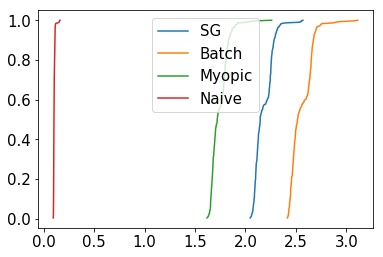

In [73]:
import matplotlib.pyplot as plt
num_user = 10
# Set Font Size Limitations
font = {'family' : 'normal',
        'weight' : 'normal',
        'size'   : 15}

plt.rc('font', **font)

plt.figure()#figsize=(7, 4))
plt.plot(df_SG['value'],df_SG['cdf'], label = 'SG')
plt.plot(df_Batch['value'],df_Batch['cdf'], label = 'Batch')
plt.plot(df_Myopic['value'],df_Myopic['cdf'], label = 'Myopic')
plt.plot(df_Naive['value'],df_Naive['cdf'], label = 'Naive')



plt.legend()

In [72]:
np.array(df_Naive['value'])

array([0.09532685, 0.09577773, 0.0960243 , 0.09618653, 0.09634472,
       0.09636489, 0.09644973, 0.09648885, 0.0965608 , 0.09686591,
       0.0969338 , 0.09699736, 0.09707789, 0.09711674, 0.09721636,
       0.097368  , 0.09746252, 0.09750104, 0.09759988, 0.09761537,
       0.09772082, 0.09774329, 0.09775735, 0.0977801 , 0.09778639,
       0.09781091, 0.09792027, 0.09795171, 0.09795213, 0.09802259,
       0.09807356, 0.09813837, 0.09816523, 0.0981927 , 0.09828096,
       0.09828984, 0.09836084, 0.09837036, 0.09837282, 0.09838837,
       0.09838877, 0.0984523 , 0.09845682, 0.09845877, 0.09850566,
       0.09859369, 0.09860199, 0.098634  , 0.09869175, 0.09872517,
       0.09873069, 0.09874402, 0.09875892, 0.09877761, 0.09884602,
       0.0989237 , 0.09894763, 0.09897872, 0.09899791, 0.09904933,
       0.09909941, 0.09911057, 0.0991204 , 0.09917078, 0.09917377,
       0.09919417, 0.09920908, 0.0992285 , 0.09925669, 0.09928658,
       0.0993172 , 0.09933947, 0.09936111, 0.09937855, 0.09939